In [1]:
import geopandas as gpd
import osmnx as ox
import matplotlib.pyplot as plt

# --- STEP 1: Load EV Charger GeoJSON ---
ev_file_path = "electric_public_fuel_stations_historical_day_Dec312023.geojson"
ev_chargers = gpd.read_file(ev_file_path)
ev_chargers

# Fetch highways using a simpler, broader filter
# 'primary' and 'motorway' are the big ones (I-5, I-90, etc.)
# print("Downloading Washington highways...")
# G = ox.graph_from_place("Washington State, USA", 
#                          network_type='drive', 
#                          custom_filter='["highway"~"motorway|motorway_link|primary"]')

# # Convert the graph to a GeoDataFrame
# # This turns the mathematical nodes/edges into actual lines we can plot
# nodes, highways_gdf = ox.graph_to_gdfs(G)


,access_code,access_days_time,access_detail_code,cards_accepted,date_last_confirmed,expected_date,fuel_type_code,groups_with_access_code,id,maximum_vehicle_class,...,nps_unit_name,access_days_time_fr,intersection_directions_fr,bd_blends_fr,groups_with_access_code_fr,ev_pricing_fr,ev_charging_units,ev_network_ids,federal_agency,geometry
0,public,24 hours daily,None,None,2023-01-10,None,ELEC,Public,33351,LD,...,None,None,None,None,Public,None,"[ { ""network"": ""Non-Networked"", ""connectors"": ...",None,None,POINT (-122.82240 47.04401)
1,public,24 hours daily; pay lot; Drivers must bring th...,None,None,2023-12-13,None,ELEC,Public,33717,LD,...,None,None,None,None,Public,None,"[ { ""network"": ""Non-Networked"", ""connectors"": ...",None,None,POINT (-122.29623 47.44338)
2,public,24 hours daily; Drivers must bring their own J...,None,None,2023-06-12,None,ELEC,Public,35620,LD,...,None,None,None,None,Public,None,"[ { ""network"": ""Non-Networked"", ""connectors"": ...",None,None,POINT (-117.38893 47.67335)
3,public,24 hours daily,None,None,2023-04-06,None,ELEC,Public,35621,LD,...,None,None,None,None,Public,None,"[ { ""network"": ""Non-Networked"", ""connectors"": ...",None,None,POINT (-117.42366 47.65579)
4,public,24 hours daily,None,None,2023-12-30,None,ELEC,Public,37181,None,...,None,None,None,None,Public,None,"[ { ""network"": ""ChargePoint Network"", ""connect...","{'station': ['USCPIL479461'], 'posts': ['65319...",None,POINT (-122.19316 47.61474)
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
2043,public,24 hours daily; for Tesla use only,CREDIT_CARD_ALWAYS,A D Debit M V,None,None,ELEC,Public - Credit card at all times,322840,LD,...,None,None,None,None,Public - Carte de crédit en tout temps,None,"[ { ""network"": ""Tesla"", ""connectors"": { ""J1772...",None,None,POINT (-122.56972 47.71362)
2044,public,24 hours daily,None,None,2023-12-30,None,ELEC,Public,323045,None,...,None,None,None,None,Public,None,"[ { ""network"": ""ChargePoint Network"", ""connect...","{'station': ['USCPIL14057821'], 'posts': ['235...",None,POINT (-122.55456 45.68473)
2045,public,24 hours daily,None,None,2023-12-30,None,ELEC,Public,323070,None,...,None,None,None,None,Public,None,"[ { ""network"": ""ChargePoint Network"", ""connect...","{'station': ['USCPIL15276601'], 'posts': ['248...",None,POINT (-123.42280 48.11619)
2046,public,24 hours daily,None,None,2023-12-30,None,ELEC,Public,323341,None,...,None,None,None,None,Public,None,"[ { ""network"": ""ChargePoint Network"", ""connect...","{'station': ['USCPIL15285201'], 'posts': ['248...",None,POINT (-122.86867 46.54583)


In [2]:
# only need to fetch this once
# !wget -O washington-latest.geojson https://download.geofabrik.de/north-america/us/washington-latest.osm.pbf

import os
import psutil
print(f"Available RAM: {psutil.virtual_memory().available / 1024**3:.2f} GB")

def print_memory():
    process = psutil.Process(os.getpid())
    print(f"Current Usage: {process.memory_info().rss / 1024**3:.2f} GB")

print_memory()

# this was run in Terminal (after installing Java 17) to pre-process the road network
# osmosis \
# >   --read-pbf washington-latest.osm.pbf \
# >   --bounding-box left=-122.8 bottom=47.1 right=-122.0 top=48.1 \
# >   --tf accept-ways highway=motorway,motorway_link,primary,primary_link,secondary \
# >   --used-node \
# >   --write-pbf seattle_corridor.osm.pbf


Available RAM: 59.35 GB
Current Usage: 0.24 GB


In [3]:
# this can take a long time but it works
# !pip install pyrosm

# Successfully built pyrosm cykhash
# Installing collected packages: cykhash, shapely, python-rapidjson, cython, pyrobuf, pyrosm
#   WARNING: The scripts cygdb, cython and cythonize are installed in '/home/jovyan/.local/geoai-py3-0.9.5/bin' which is not on PATH.
#   Consider adding this directory to PATH or, if you prefer to suppress this warning, use --no-warn-script-location.
#   WARNING: The script pyrobuf is installed in '/home/jovyan/.local/geoai-py3-0.9.5/bin' which is not on PATH.
#   Consider adding this directory to PATH or, if you prefer to suppress this warning, use --no-warn-script-location.
# ERROR: pip's dependency resolver does not currently take into account all the packages that are installed. This behaviour is the source of the following dependency conflicts.
# osmnx 1.2.3 requires pyproj>=3.4, but you have pyproj 3.3.0 which is incompatible.
# osmnx 1.2.3 requires Shapely<2.0,>=1.8, but you have shapely 2.0.7 which is incompatible.
# Successfully installed cykhash-2.0.1 cython-3.2.4 pyrobuf-0.9.3 pyrosm-0.6.2 python-rapidjson-1.23 shapely-2.0.7

from pyrosm import OSM
import shapely
print(f"Shapely version: {shapely.__version__}") # Should be 2.0.7


Shapely version: 1.8.0


In [4]:
import gc

# Define the Metro Bounding Box [min_lon, min_lat, max_lon, max_lat]
# This covers from south of Tacoma to north of Everett
# metro_bbox = [-122.8, 47.1, -122.0, 48.1]

pbf_path = "seattle_corridor.osm.pbf" 

osm = OSM(pbf_path)
metro_roads = osm.get_network(network_type="driving")

# Initialize the OSM object with bounding box
# osm = OSM("washington-latest.osm.pbf", bounding_box=metro_bbox)

print_memory()
metro_roads = osm.get_network(network_type="driving")
# Filter for the main arteries
highway_types = ["motorway", "motorway_link", "primary", "primary_link", "secondary"]
metro_roads = metro_roads[metro_roads["highway"].isin(highway_types)].copy()

# Try using a custom filter instead of get_network() to save RAM
# This only pulls the "ways" that match your highway types
# custom_filter = {"highway": ["motorway", "motorway_link", "primary", "primary_link", "secondary"]}
# metro_roads = osm.get_data_by_custom_criteria(custom_filter=custom_filter)
# print_memory()

# Explicitly clear the reader object once data is in a GeoDataFrame
# del osm
gc.collect()

print(f"Success! {len(metro_roads)} segments ready for mapping.")
print(metro_roads[['name', 'highway', 'geometry']].head())

# print(f"Success! {len(metro_roads)} segments ready for mapping.")

Current Usage: 0.57 GB
Success! 29714 segments ready for mapping.
   name        highway                                           geometry
0  None       motorway  MULTILINESTRING ((-122.31778 47.64274, -122.31...
1  None  motorway_link  MULTILINESTRING ((-122.32263 47.63854, -122.32...
2  None  motorway_link  MULTILINESTRING ((-122.30494 47.64340, -122.30...
3  None  motorway_link  MULTILINESTRING ((-122.30891 47.64331, -122.30...
4  None  motorway_link  MULTILINESTRING ((-122.30488 47.64442, -122.30...


EV Bounds: [-124.662924   45.562567 -117.043496   48.995255]
Highway Bounds: [-122.7999831   47.1000074 -122.0000996   48.0999994]


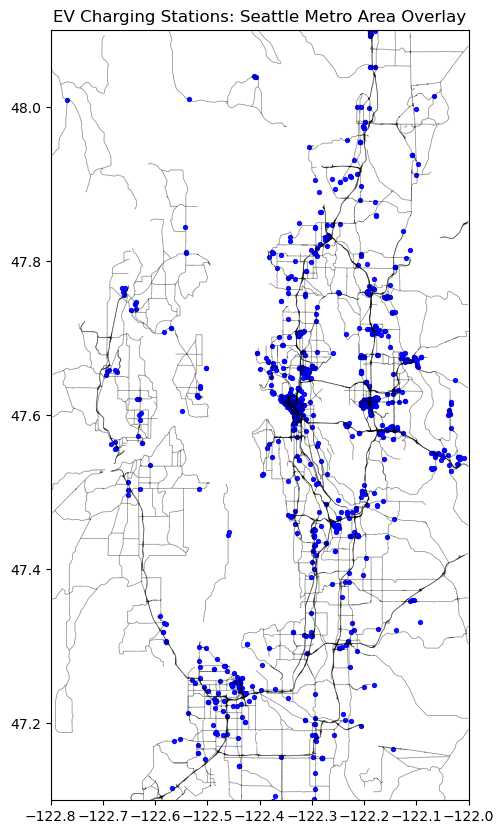

In [5]:
# transform EV chargers to Lat/Long
ev_chargers = ev_chargers.to_crs(epsg=4326)

# transform Highways to Lat/Long 
metro_roads = metro_roads.to_crs(epsg=4326)

# Diagnostic
print(f"EV Bounds: {ev_chargers.total_bounds}")
print(f"Highway Bounds: {metro_roads.total_bounds}")

fig, ax = plt.subplots(figsize=(15, 10))

# Plot highways first
#highways_gdf.plot(ax=ax, linewidth=0.6, color='black', alpha=0.5)
metro_roads.plot(ax=ax, color='black', linewidth=0.5, alpha=0.5)

# Plot chargers on top
ev_chargers.plot(ax=ax, markersize=8, color='blue', alpha=0.9, label='EV Chargers')

# MANUALLY FORCE THE VIEW to match Seattle Metro GPS box
# Osmosis bounding box left=-122.8 bottom=47.1 right=-122.0 top=48.1 \
ax.set_xlim(-122.8, -122.0)
ax.set_ylim(47.1, 48.1)

ax.set_title("EV Charging Stations: Seattle Metro Area Overlay")
plt.show()

In [6]:
import pandas as pd
# Load all AAA incidents
aaa_df = pd.read_csv("AAA_OutofChargeWA_Nov22-Nov23.csv")

In [7]:
aaa_df_out = aaa_df[aaa_df["ERS_CATEGORY"]=="Out of Fuel / Low Fuel/Out of Charge"]
# Highway Bounds: [min_lon, min_lat, max_lon, max_lat]
min_lon, min_lat, max_lon, max_lat = [-122.79998016, 47.1000061, -122.00009918, 48.09999847]

# Filter the dataframe
aaa_metro_ooc = aaa_df_out[
    (aaa_df_out['ERS_LONGITUDE'] >= min_lon) & 
    (aaa_df_out['ERS_LONGITUDE'] <= max_lon) & 
    (aaa_df_out['ERS_LATITUDE'] >= min_lat) & 
    (aaa_df_out['ERS_LATITUDE'] <= max_lat)
].copy()

print(f"Filtered AAA incidents in metro corridor: {len(aaa_metro_ooc)}")

Filtered AAA incidents in metro corridor: 39


In [8]:
aaa_ooc_incidents = gpd.GeoDataFrame(
    aaa_metro_ooc, 
    geometry=gpd.points_from_xy(aaa_metro_ooc.ERS_LONGITUDE, aaa_metro_ooc.ERS_LATITUDE),
    crs="EPSG:4326"
).to_crs(epsg=32610) # Project to UTM 10N (meters)

In [9]:
# project to UTM 10N also
existing_chargers = ev_chargers.to_crs(epsg=32610)

# calculate distance to nearest charger for every incident
def min_dist(point, other_gdf):
    # Returns distance in meters
    return other_gdf.distance(point).min()

aaa_ooc_incidents['dist_to_charger_m'] = aaa_ooc_incidents.geometry.apply(min_dist, args=(existing_chargers,))

In [10]:
# Calculate distance to nearest existing station for each breakdown
aaa_ooc_incidents['dist_to_nearest_km'] = aaa_ooc_incidents.geometry.apply(
    lambda x: existing_chargers.distance(x).min() / 1000
)

# Summary Stats for your report
print(f"Average distance to nearest charger: {aaa_ooc_incidents['dist_to_nearest_km'].mean():.2f} km")
print(f"Max distance (Worst Case): {aaa_ooc_incidents['dist_to_nearest_km'].max():.2f} km")

Average distance to nearest charger: 1.11 km
Max distance (Worst Case): 3.83 km


In [11]:
import networkx as nx

nodes, edges = osm.get_network(nodes=True, network_type="driving")

candidate_sites = nodes # These are the candidate locations at intersection of two or more roads

# Convert pyrosm network to an OSMnx-compatible graph
G = osm.to_graph(nodes, edges, graph_type="networkx")

# Find nearest node for each incident and station
orig_nodes = ox.nearest_nodes(G, aaa_ooc_incidents.geometry.x, aaa_ooc_incidents.geometry.y)
dest_nodes = ox.nearest_nodes(G, existing_chargers.geometry.x, existing_chargers.geometry.y)

# Calculate shortest network path distance f
# This is much more accurate than straight-line distance
def get_network_dist(orig, dest, graph):
    try:
        return nx.shortest_path_length(graph, orig, dest, weight='length')
    except nx.NetworkNoPath:
        return float('inf')

# Example for a single pair
dist = get_network_dist(orig_nodes[0], dest_nodes[0], G)


In [54]:
dist

31316.833999999988

In [43]:
# Create 1km and 3km "Service Bubbles" around chargers
buffer_1km = existing_chargers.buffer(1000).unary_union
buffer_3km = existing_chargers.buffer(3000).unary_union

# Check how many incidents fall OUTSIDE these zones
incidents_outside_1km = aaa_ooc_incidents[~aaa_ooc_incidents.geometry.within(buffer_1km)]
incidents_outside_3km = aaa_ooc_incidents[~aaa_ooc_incidents.geometry.within(buffer_3km)]

print(f"Incidents in 'Deserts' (>1km from charger): {len(incidents_outside_1km)}")
print(f"Incidents in 'Critical Deserts' (>3km from charger): {len(incidents_outside_3km)}")

Incidents in 'Deserts' (>1km from charger): 16
Incidents in 'Critical Deserts' (>3km from charger): 5


/tmp/ipykernel_604/107102258.py:30: UserWarning: Legend does not support handles for PatchCollection instances.
See: https://matplotlib.org/stable/tutorials/intermediate/legend_guide.html#implementing-a-custom-legend-handler
  ax.legend(loc='upper right')


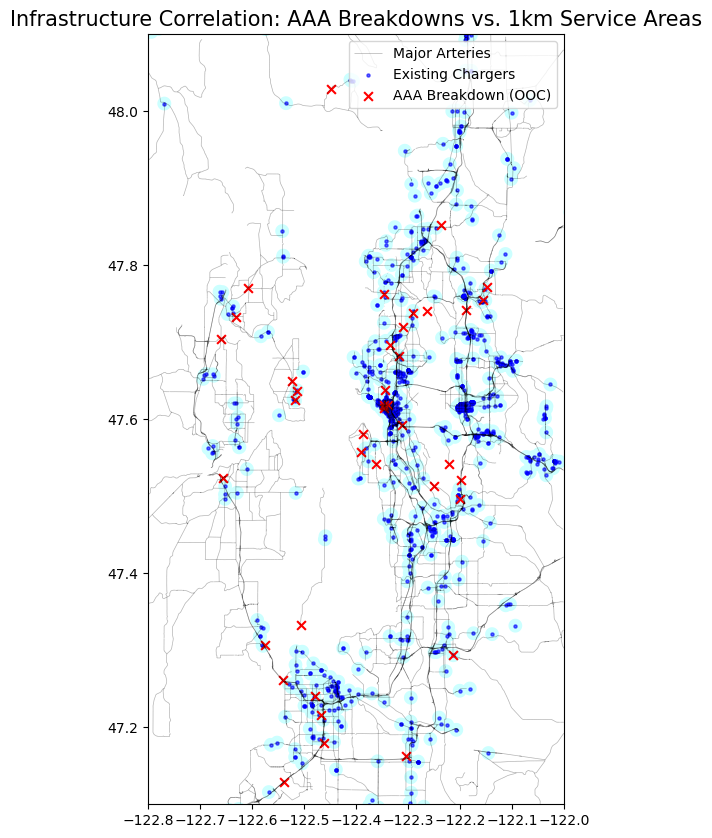

In [50]:
# Prepare the buffer layer for plotting
# Convert the 1km buffer from meters back to degrees
buffer_1km_gdf = gpd.GeoDataFrame(geometry=[buffer_1km], crs="EPSG:32610").to_crs(epsg=4326)

fig, ax = plt.subplots(figsize=(15, 10))

# get incident locations back to lat/lon for plotting
aaa_ooc_plot = aaa_ooc_incidents.to_crs(epsg=4326)

# Layer 1: The Road Network
metro_roads.plot(ax=ax, color='black', linewidth=0.5, alpha=0.3, label='Major Arteries')

# Layer 2: The Service Area (The 1km "Bubbles")
# Areas NOT covered by these blue circles are your "Deserts"
buffer_1km_gdf.plot(ax=ax, color='cyan', alpha=0.2, label='1km Service Area')

# Layer 3: Existing EV Chargers
ev_chargers.plot(ax=ax, markersize=5, color='blue', alpha=0.6, label='Existing Chargers')

# Layer 4: AAA "Out of Charge" Incidents (The Demand)
# Points outside the cyan bubbles are the "Proof" of the infrastructure gap
aaa_ooc_plot.plot(ax=ax, markersize=40, color='red', marker='x', label='AAA Breakdown (OOC)')

# Set View Limits
ax.set_xlim(-122.8, -122.0)
ax.set_ylim(47.1, 48.1)

# Formatting
ax.set_title("Infrastructure Correlation: AAA Breakdowns vs. 1km Service Areas", fontsize=15)
ax.legend(loc='upper right')
plt.show()


In [55]:
from spopt.locate import PMedian
from scipy.spatial.distance import cdist

# demand is already in meters
demand_coords = np.array(list(zip(aaa_ooc_incidents.geometry.x, aaa_ooc_incidents.geometry.y)))

# create candidate grid for potential facility locations every 2km within the corridor
x_range = np.arange(aaa_ooc_incidents.total_bounds[0], aaa_ooc_incidents.total_bounds[2], 2000)
y_range = np.arange(aaa_ooc_incidents.total_bounds[1], aaa_ooc_incidents.total_bounds[3], 2000)
grid_points = np.array(np.meshgrid(x_range, y_range)).T.reshape(-1, 2)

# Calculate Distance Matrix (d_ij) between 39 incidents and ~800 grid points
dist_matrix = cdist(demand_coords, grid_points)


In [ ]:
from pulp import LpVariable, LpProblem, LpMinimize, lpSum, LpStatus

# Define Facilities (Grid Points) and Demand (AAA Incidents)
# Using our already-calculated 'cost_matrix' (39 x 800ish)
num_demand = range(len(demand_coords))
num_facilities = range(len(grid_points))

# Declare variables
# X[j] is 1 if we place a facility at grid point j
X = LpVariable.dicts('X', num_facilities, cat='Binary')

# Y[i][j] is 1 if demand i is served by facility j
Y = LpVariable.dicts('Y', (num_demand, num_facilities), cat='Binary')

# Initialize Problem
prob_pcenter = LpProblem('Seattle_EV_Optimization', LpMinimize)

# Objective Function: Minimize total distance
# d_ij is cost_matrix[i][j]
prob_pcenter += lpSum(dist_matrix[i][j] * Y[i][j] for i in num_demand for j in num_facilities)

# Constraints: exactly p facilities
prob_pcenter += lpSum(X[j] for j in num_facilities) == 15

# Each demand node must be served by exactly one facility
for i in num_demand:
    prob_pcenter += lpSum(Y[i][j] for j in num_facilities) == 1

# A demand node can only be served by j if facility j is open
for i in num_demand:
    for j in num_facilities:
        prob_pcenter += Y[i][j] <= X[j]

print("Solving... this may take 1-2 minutes for ~30k variables.")
prob_pcenter.solve()

# print(f"Status: {LpStatus[prob_pcenter.status]}")


In [66]:
optimal_indices

[22, 84, 210, 250, 278, 355, 449, 524, 627, 683, 702, 840, 859, 872, 985]

In [67]:
# Extract indices where X[j] was set to 1
optimal_indices = [j for j in num_facilities if X[j].varValue == 1]
optimal_coords = grid_points[optimal_indices]

# Create GeoDataFrame for the map
optimal_gdf = gpd.GeoDataFrame(
    geometry=gpd.points_from_xy(optimal_coords[:, 0], optimal_coords[:, 1]),
    crs="EPSG:32610"
).to_crs(epsg=4326)

/tmp/ipykernel_604/324603363.py:29: UserWarning: Legend does not support handles for PatchCollection instances.
See: https://matplotlib.org/stable/tutorials/intermediate/legend_guide.html#implementing-a-custom-legend-handler
  ax.legend(loc='upper right', prop={'size': 10}, frameon=True)


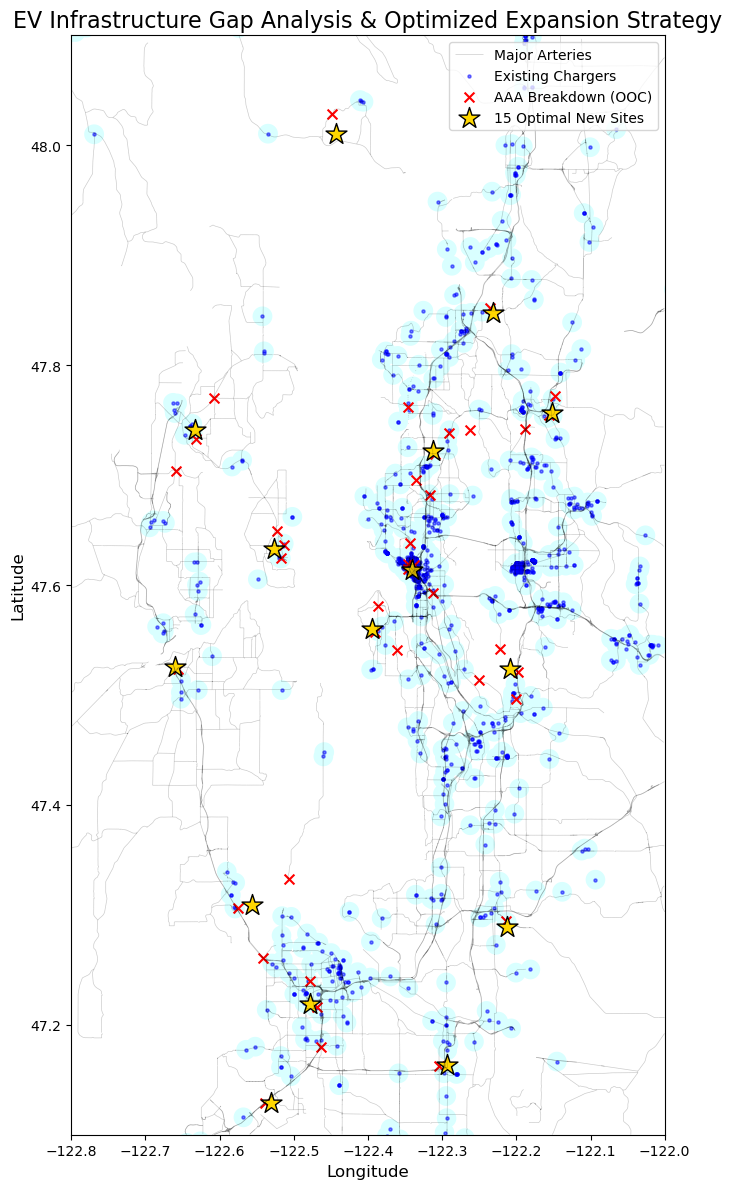

In [64]:
fig, ax = plt.subplots(figsize=(15, 12))

# Layer 1: major roads
metro_roads.plot(ax=ax, color='black', linewidth=0.5, alpha=0.2, label='Major Arteries')

# Layer 2: the presumed service area: 1km Bubbles
buffer_1km_gdf.plot(ax=ax, color='cyan', alpha=0.15, label='1km Service Area')

# Layer 3: existing EV Charging infrastructure
ev_chargers.plot(ax=ax, markersize=5, color='blue', alpha=0.5, label='Existing Chargers')

# Layer 4: AAA Out of Charge Incidents (demand points)
aaa_ooc_plot.plot(ax=ax, markersize=50, color='red', marker='x', label='AAA Breakdown (OOC)')

# Layer 5: 15 Optimal New Sites (The P-Median Solution)
# These should land in the white spaces/deserts to solve the gap
optimal_gdf.plot(ax=ax, markersize=250, color='gold', marker='*', 
                 edgecolor='black', linewidth=1, label='15 Optimal New Sites')

# Set View Limits to the Metro Seattle Bounding Box
ax.set_xlim(-122.8, -122.0)
ax.set_ylim(47.1, 48.1)

# Formatting for academic presentation
ax.set_title("EV Infrastructure Gap Analysis & Optimized Expansion Strategy", fontsize=16)
ax.set_xlabel("Longitude", fontsize=12)
ax.set_ylabel("Latitude", fontsize=12)
ax.legend(loc='upper right', prop={'size': 10}, frameon=True)

plt.tight_layout()
plt.show()


In [72]:
from sklearn.cluster import KMeans
import numpy as np

# Use K-Means to find 15 Central centroids of 39 incidents
kmeans = KMeans(n_clusters=15, random_state=42, n_init=10).fit(demand_coords)
initial_centers = kmeans.cluster_centers_

# Snap centroids to the nearest real Grid Points
# This ensures our 15 sites are on the 'candidate' locations we defined
optimal_indices_kmeans = []
for center in initial_centers:
    # Find the index of the grid point with the minimum distance to this centroid
    dist = np.linalg.norm(grid_points - center, axis=1)
    optimal_indices_kmeans.append(np.argmin(dist))

optimal_coords_kmeans = grid_points[optimal_indices_kmeans]

optimal_gdf_kmeans = gpd.GeoDataFrame(
    geometry=gpd.points_from_xy(optimal_coords_kmeans[:, 0], optimal_coords_kmeans[:, 1]),
    crs="EPSG:32610"
).to_crs(epsg=4326)

print(f"Successfully calculated {len(optimal_gdf_kmeans)} optimal locations via heuristic.")

Successfully calculated 15 optimal locations via heuristic.


In [75]:
optimal_indices_kmeans

[22, 84, 250, 259, 278, 355, 449, 574, 627, 683, 702, 840, 859, 872, 985]

This is only one different node than the P-Center solution, index 259 instead of 210 which helps validate our findings.